<a href="https://colab.research.google.com/github/LorenzoCag/horizon/blob/main/capbike.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
import os

data_path = "/content/drive/MyDrive/capitalbike"

files = os.listdir(data_path)

print(f"Found {len(files)} files")
print(files[:10])

Found 1 files
['capitalbikedata']


In [4]:
import os
import glob
import pandas as pd

# Base directory where all your yearly folders are located
base_path = "/content/drive/MyDrive/capitalbike/capitalbikedata"

# Find all zip files recursively in the subfolders
zip_files = sorted(glob.glob(os.path.join(base_path, "**/*.zip"), recursive=True))

print(f"Found {len(zip_files)} ZIP files in your dataset directories.")
if zip_files:
    print("Example files:")
    for f in zip_files[:5]:
        print(f" - {f}")

Found 48 ZIP files in your dataset directories.
Example files:
 - /content/drive/MyDrive/capitalbike/capitalbikedata/2022-capitalbikedata/202201-capitalbikeshare-tripdata.zip
 - /content/drive/MyDrive/capitalbike/capitalbikedata/2022-capitalbikedata/202202-capitalbikeshare-tripdata.zip
 - /content/drive/MyDrive/capitalbike/capitalbikedata/2022-capitalbikedata/202203-capitalbikeshare-tripdata.zip
 - /content/drive/MyDrive/capitalbike/capitalbikedata/2022-capitalbikedata/202204-capitalbikeshare-tripdata.zip
 - /content/drive/MyDrive/capitalbike/capitalbikedata/2022-capitalbikedata/202205-capitalbikeshare-tripdata.zip


In [5]:
import zipfile

if zip_files:
    target_file = zip_files[0]
    print(f"Reading data from: {target_file}")

    # Open the zip archive and find the real CSV file, ignoring macOS metadata
    with zipfile.ZipFile(target_file, 'r') as z:
        # Filter out metadata files starting with __MACOSX or ._
        csv_files = [f for f in z.namelist() if f.endswith('.csv') and not f.startswith('__MACOSX')]

        if csv_files:
            csv_to_read = csv_files[0]
            print(f"Loading extracted CSV file: {csv_to_read}")
            with z.open(csv_to_read) as f:
                df_sample = pd.read_csv(f)
                display(df_sample.head())
        else:
            print("No valid CSV file found inside the zip archive.")

Reading data from: /content/drive/MyDrive/capitalbike/capitalbikedata/2022-capitalbikedata/202201-capitalbikeshare-tripdata.zip
Loading extracted CSV file: 202201-capitalbikeshare-tripdata.csv


,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual
0,1B4445D591115BD9,classic_bike,2022-01-06 18:39:28,2022-01-06 18:43:03,Monroe Ave & Leslie Ave,31087.0,Potomac Ave & Main Line Blvd,31910.0,38.820932,-77.053096,38.822738,-77.049265,member
1,7F4A0E2F03EADEB7,classic_bike,2022-01-31 19:21:22,2022-01-31 19:27:33,14th & L St NW,31283.0,10th & G St NW,31274.0,38.903658,-77.031737,38.898243,-77.026235,member
2,30DD8A84164843AD,classic_bike,2022-01-07 15:28:39,2022-01-07 15:31:01,14th & L St NW,31283.0,12th & L St NW,31251.0,38.903658,-77.031737,38.903819,-77.028400,member
3,FC67665D7682D0A6,classic_bike,2022-01-27 20:09:25,2022-01-27 20:37:02,New York Ave & Hecht Ave NE,31518.0,Nannie Helen Burroughs & Minnesota Ave NE,31704.0,38.915604,-76.983683,38.901385,-76.941877,casual
4,7854F7CC4F631A1E,classic_bike,2022-01-07 16:14:28,2022-01-07 16:16:13,Falls Church City Hall / Park Ave & Little Fal...,32608.0,Pennsylvania Ave & Park Ave,32603.0,38.885434,-77.173605,38.887403,-77.176992,member


In [6]:
import zipfile
import os
import pandas as pd

table_details = []

print(f"Scanning {len(zip_files)} archives to gather table details...")

for file_path in zip_files:
    folder_name = os.path.basename(os.path.dirname(file_path))
    zip_name = os.path.basename(file_path)

    with zipfile.ZipFile(file_path, 'r') as z:
        csv_files = [f for f in z.namelist() if f.endswith('.csv') and not f.startswith('__MACOSX')]
        if csv_files:
            csv_name = csv_files[0]
            with z.open(csv_name) as f:
                # Read just the header first to get column details quickly
                df_temp = pd.read_csv(f, nrows=5)
                columns = list(df_temp.columns)
                num_cols = len(columns)

            # Get total row count by reading the CSV in chunks (memory-efficient)
            with z.open(csv_name) as f:
                row_count = sum(len(chunk) for chunk in pd.read_csv(f, chunksize=50000))

            table_details.append({
                'Folder': folder_name,
                'Zip File': zip_name,
                'Internal CSV': csv_name,
                'Rows': row_count,
                'Columns Count': num_cols,
                'Columns': columns
            })

# Create a summary DataFrame of all tables
summary_df = pd.DataFrame(table_details)
display(summary_df)

Scanning 48 archives to gather table details...


,Folder,Zip File,Internal CSV,Rows,Columns Count,Columns
0,2022-capitalbikedata,202201-capitalbikeshare-tripdata.zip,202201-capitalbikeshare-tripdata.csv,109619,13,"[ride_id, rideable_type, started_at, ended_at,..."
1,2022-capitalbikedata,202202-capitalbikeshare-tripdata.zip,202202-capitalbikeshare-tripdata.csv,154317,13,"[ride_id, rideable_type, started_at, ended_at,..."
2,2022-capitalbikedata,202203-capitalbikeshare-tripdata.zip,202203-capitalbikeshare-tripdata.csv,254250,13,"[ride_id, rideable_type, started_at, ended_at,..."
3,2022-capitalbikedata,202204-capitalbikeshare-tripdata.zip,202204-capitalbikeshare-tripdata.csv,310435,13,"[ride_id, rideable_type, started_at, ended_at,..."
4,2022-capitalbikedata,202205-capitalbikeshare-tripdata.zip,202205-capitalbikeshare-tripdata.csv,332821,13,"[ride_id, rideable_type, started_at, ended_at,..."
5,2022-capitalbikedata,202206-capitalbikeshare-tripdata.zip,202206-capitalbikeshare-tripdata.csv,389656,13,"[ride_id, rideable_type, started_at, ended_at,..."
6,2022-capitalbikedata,202207-capitalbikeshare-tripdata.zip,202207-capitalbikeshare-tripdata.csv,393683,13,"[ride_id, rideable_type, started_at, ended_at,..."
7,2022-capitalbikedata,202208-capitalbikeshare-tripdata.zip,202208-capitalbikeshare-tripdata.csv,377657,13,"[ride_id, rideable_type, started_at, ended_at,..."
8,2022-capitalbikedata,202209-capitalbikeshare-tripdata.zip,202209-capitalbikeshare-tripdata.csv,386085,13,"[ride_id, rideable_type, started_at, ended_at,..."
9,2022-capitalbikedata,202210-capitalbikeshare-tripdata.zip,202210-capitalbikeshare-tripdata.csv,333309,13,"[ride_id, rideable_type, started_at, ended_at,..."


In [7]:
# Print overall summary details
total_rows = summary_df['Rows'].sum()
print(f"Total tables found: {len(summary_df)}")
print(f"Total combined row count across all datasets: {total_rows:,}")

# Check if all tables share identical columns
first_set_cols = set(summary_df.iloc[0]['Columns'])
all_identical = all(set(cols) == first_set_cols for cols in summary_df['Columns'])
print(f"Do all tables have identical columns?: {all_identical}")

Total tables found: 48
Total combined row count across all datasets: 20,721,086
Do all tables have identical columns?: True


### Phase 1: Ingestion and Validation Pipeline

We configure a pipeline using **DuckDB** to stream the CSVs, perform data quality checks (duplicates, nulls, invalid dates), and log the quality issues without loading all data into RAM.

In [8]:
import os
import zipfile
import duckdb
import pandas as pd
import time

# Create local storage directories
output_dir = "/content/data"
os.makedirs(output_dir, exist_ok=True)
os.makedirs(os.path.join(output_dir, "parquet_dataset"), exist_ok=True)

# Initialize local DuckDB connection
con = duckdb.connect()

validation_reports = []

print("Starting ingestion & validation pipeline...")
t0 = time.time()

for idx, zip_path in enumerate(zip_files):
    month_label = os.path.basename(zip_path).replace("-capitalbikeshare-tripdata.zip", "")
    print(f"[{idx+1}/{len(zip_files)}] Processing {month_label}...")

    with zipfile.ZipFile(zip_path, 'r') as z:
        csv_files = [f for f in z.namelist() if f.endswith('.csv') and not f.startswith('__MACOSX')]
        if not csv_files:
            continue

        csv_name = csv_files[0]
        # Extract zip locally to the temporary Colab workspace for optimal DuckDB reading speed
        z.extract(csv_name, path="/tmp")
        temp_csv_path = os.path.join("/tmp", csv_name)

        try:
            # Register temporary table in DuckDB
            con.execute(f"CREATE OR REPLACE TEMPORARY TABLE temp_raw AS SELECT * FROM read_csv_auto('{temp_csv_path}')")

            # Validate constraints using SQL
            total_records = con.execute("SELECT COUNT(*) FROM temp_raw").fetchone()[0]
            missing_ride_id = con.execute("SELECT COUNT(*) FROM temp_raw WHERE ride_id IS NULL").fetchone()[0]
            missing_timestamps = con.execute("SELECT COUNT(*) FROM temp_raw WHERE started_at IS NULL OR ended_at IS NULL").fetchone()[0]
            duplicate_rides = con.execute("SELECT COUNT(*) FROM (SELECT ride_id FROM temp_raw GROUP BY ride_id HAVING COUNT(*) > 1)").fetchone()[0]
            invalid_times = con.execute("SELECT COUNT(*) FROM temp_raw WHERE CAST(ended_at AS TIMESTAMP) < CAST(started_at AS TIMESTAMP)").fetchone()[0]
            missing_stations = con.execute("SELECT COUNT(*) FROM temp_raw WHERE start_station_name IS NULL OR end_station_name IS NULL").fetchone()[0]

            validation_reports.append({
                "month": month_label,
                "total_records": total_records,
                "missing_ride_id": missing_ride_id,
                "missing_timestamps": missing_timestamps,
                "duplicate_rides": duplicate_rides,
                "invalid_times": invalid_times,
                "missing_stations": missing_stations
            })

        finally:
            # Clean up the extracted CSV file to preserve Colab local disk space
            if os.path.exists(temp_csv_path):
                os.remove(temp_csv_path)

# Consolidate and display validation report
validation_df = pd.DataFrame(validation_reports)
display(validation_df.head(10))
print(f"Validation completed in {(time.time() - t0)/60:.2f} minutes.")

Starting ingestion & validation pipeline...
[1/48] Processing 202201...
[2/48] Processing 202202...
[3/48] Processing 202203...
[4/48] Processing 202204...
[5/48] Processing 202205...
[6/48] Processing 202206...
[7/48] Processing 202207...
[8/48] Processing 202208...
[9/48] Processing 202209...
[10/48] Processing 202210...
[11/48] Processing 202211...
[12/48] Processing 202212...
[13/48] Processing 202301...
[14/48] Processing 202302...
[15/48] Processing 202303...
[16/48] Processing 202304...
[17/48] Processing 202305...
[18/48] Processing 202306...
[19/48] Processing 202307...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[20/48] Processing 202308...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[21/48] Processing 202309...
[22/48] Processing 202310...


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

... (7 outputs left out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

[43/48] Processing 202507...
[44/48] Processing 202508...
[45/48] Processing 202509...
[46/48] Processing 202510...
[47/48] Processing 202511...
[48/48] Processing 202512...


,month,total_records,missing_ride_id,missing_timestamps,duplicate_rides,invalid_times,missing_stations
0,202201,109619,0,0,0,7,9580
1,202202,154317,0,0,0,3,11471
2,202203,254250,0,0,0,7,17063
3,202204,310435,0,0,0,5,22491
4,202205,332821,0,0,0,7,22020
5,202206,389656,0,0,0,7,25795
6,202207,393683,0,0,0,7,23756
7,202208,377657,0,0,0,4,21807
8,202209,386085,0,0,0,6,20117
9,202210,333309,0,0,0,11,18179


Validation completed in 1.90 minutes.


In [9]:
print("Total trips:", f"{validation_df['total_records'].sum():,}")

print("\nValidation totals:")
print(
    validation_df[
        [
            "missing_ride_id",
            "missing_timestamps",
            "duplicate_rides",
            "invalid_times",
            "missing_stations"
        ]
    ].sum()
)

Total trips: 20,721,086

Validation totals:
missing_ride_id             0
missing_timestamps          0
duplicate_rides             0
invalid_times            1108
missing_stations      4651177
dtype: int64


In [10]:
import zipfile
import pandas as pd

results = []

for zip_path in sorted(zip_files):
    with zipfile.ZipFile(zip_path) as z:
        csv_name = next(
            name for name in z.namelist()
            if name.endswith(".csv") and not name.startswith("__MACOSX")
        )

        with z.open(csv_name) as f:
            df = pd.read_csv(
                f,
                usecols=[
                    "rideable_type",
                    "start_station_id",
                    "end_station_id"
                ]
            )

    for bike_type, group in df.groupby("rideable_type"):
        results.append({
            "month": zip_path.split("/")[-1][:6],
            "rideable_type": bike_type,
            "total_trips": len(group),
            "missing_start_id": group["start_station_id"].isna().sum(),
            "missing_end_id": group["end_station_id"].isna().sum(),
            "missing_either_id": (
                group["start_station_id"].isna() |
                group["end_station_id"].isna()
            ).sum()
        })

results_df = pd.DataFrame(results)

summary = (
    results_df.groupby("rideable_type", as_index=False)
    .sum(numeric_only=True)
)

summary["missing_pct"] = (
    summary["missing_either_id"] /
    summary["total_trips"] * 100
).round(2)

display(summary)

,rideable_type,total_trips,missing_start_id,missing_end_id,missing_either_id,missing_pct
0,classic_bike,10806709,10,18334,18342,0.17
1,docked_bike,338250,0,4639,4639,1.37
2,electric_bike,9576127,3247348,3366837,4630524,48.35


In [11]:
import os
import zipfile
import pandas as pd
from collections import defaultdict

# Configuration
output_dir = "/content/data"
os.makedirs(output_dir, exist_ok=True)

departures = defaultdict(int)
arrivals = defaultdict(int)

total_filtered_trips = 0

print("Building hourly station-demand dataset...")

for idx, zip_path in enumerate(sorted(zip_files)):

    month = os.path.basename(zip_path)[:6]
    print(f"[{idx+1}/{len(zip_files)}] Processing {month}")

    with zipfile.ZipFile(zip_path) as z:

        csv_name = next(
            f for f in z.namelist()
            if f.endswith(".csv") and not f.startswith("__MACOSX")
        )

        with z.open(csv_name) as f:
            df = pd.read_csv(
                f,
                usecols=[
                    "rideable_type",
                    "started_at",
                    "ended_at",
                    "start_station_id",
                    "end_station_id"
                ],
                dtype={
                    "start_station_id": "string",
                    "end_station_id": "string"
                }
            )

    # Keep classic and docked bikes
    df = df[
        df["rideable_type"].isin(["classic_bike", "docked_bike"])
    ].copy()

    # Parse timestamps
    df["started_at"] = pd.to_datetime(df["started_at"], errors="coerce")
    df["ended_at"] = pd.to_datetime(df["ended_at"], errors="coerce")

    # Remove invalid trips
    df = df[
        df["started_at"].notna()
        & df["ended_at"].notna()
        & (df["ended_at"] >= df["started_at"])
    ]

    total_filtered_trips += len(df)

    # Aggregate departures
    dep = (
        df.dropna(subset=["start_station_id"])
        .assign(hour=lambda x: x["started_at"].dt.floor("h"))
        .groupby(["start_station_id", "hour"])
        .size()
    )

    for (station, hour), count in dep.items():
        departures[(station, hour)] += int(count)

    # Aggregate arrivals
    arr = (
        df.dropna(subset=["end_station_id"])
        .assign(hour=lambda x: x["ended_at"].dt.floor("h"))
        .groupby(["end_station_id", "hour"])
        .size()
    )

    for (station, hour), count in arr.items():
        arrivals[(station, hour)] += int(count)

# Combine departures and arrivals
all_keys = departures.keys() | arrivals.keys()

hourly_df = pd.DataFrame(
    [
        {
            "station_id": station,
            "hour": hour,
            "departures": departures.get((station, hour), 0),
            "arrivals": arrivals.get((station, hour), 0)
        }
        for station, hour in all_keys
    ]
)

hourly_df["net_change"] = (
    hourly_df["arrivals"] - hourly_df["departures"]
)

hourly_df = hourly_df.sort_values(
    ["station_id", "hour"]
).reset_index(drop=True)

# Save to Parquet
output_path = f"{output_dir}/hourly_station_demand.parquet"

hourly_df.to_parquet(output_path, index=False)

print("\nPROCESSING COMPLETE")
print(f"Valid classic/docked trips: {total_filtered_trips:,}")
print(f"Unique stations: {hourly_df['station_id'].nunique():,}")
print(f"Station-hour observations: {len(hourly_df):,}")
print(f"Saved to: {output_path}")

display(hourly_df.head(10))


Building hourly station-demand dataset...
[1/48] Processing 202201
[2/48] Processing 202202
[3/48] Processing 202203
[4/48] Processing 202204
[5/48] Processing 202205
[6/48] Processing 202206
[7/48] Processing 202207
[8/48] Processing 202208
[9/48] Processing 202209
[10/48] Processing 202210
[11/48] Processing 202211
[12/48] Processing 202212
[13/48] Processing 202301
[14/48] Processing 202302
[15/48] Processing 202303
[16/48] Processing 202304
[17/48] Processing 202305
[18/48] Processing 202306
[19/48] Processing 202307
[20/48] Processing 202308
[21/48] Processing 202309
[22/48] Processing 202310
[23/48] Processing 202311
[24/48] Processing 202312
[25/48] Processing 202401
[26/48] Processing 202402
[27/48] Processing 202403
[28/48] Processing 202404
[29/48] Processing 202405
[30/48] Processing 202406
[31/48] Processing 202407
[32/48] Processing 202408
[33/48] Processing 202409
[34/48] Processing 202410
[35/48] Processing 202411
[36/48] Processing 202412
[37/48] Processing 202501
[38/4

,station_id,hour,departures,arrivals,net_change
0,30200,2023-02-01 13:00:00,0,2,2
1,30200,2023-02-01 14:00:00,0,2,2
2,30200,2023-02-01 15:00:00,0,3,3
3,30200,2023-02-01 16:00:00,3,4,1
4,30200,2023-02-01 18:00:00,0,1,1
5,30200,2023-02-02 08:00:00,1,0,-1
6,30200,2023-02-02 11:00:00,1,0,-1
7,30200,2023-02-02 13:00:00,1,4,3
8,30200,2023-02-02 14:00:00,0,5,5
9,30200,2023-02-02 16:00:00,0,1,1


## **Data Exploration**

In [12]:
import pandas as pd

station_stats = (
    hourly_df.groupby("station_id")
    .agg(
        total_departures=("departures", "sum"),
        total_arrivals=("arrivals", "sum"),
        active_hours=("hour", "count"),
        first_seen=("hour", "min"),
        last_seen=("hour", "max")
    )
    .reset_index()
)

station_stats["total_activity"] = (
    station_stats["total_departures"] +
    station_stats["total_arrivals"]
)

station_stats = station_stats.sort_values(
    "total_activity",
    ascending=False
)

print("Top 10 busiest stations:")
display(station_stats.head(10))

print("\nBottom 10 least active stations:")
display(station_stats.tail(10))

print("\nActivity distribution:")
display(station_stats["total_activity"].describe())

Top 10 busiest stations:


,station_id,total_departures,total_arrivals,active_hours,first_seen,last_seen,total_activity
399,31623,137499,138948,28082,2022-01-01 01:00:00,2025-12-31 20:00:00,276447
173,31229,119111,117281,28489,2022-01-01 00:00:00,2025-12-31 21:00:00,236392
202,31258,109598,108763,20483,2022-01-01 00:00:00,2025-12-31 21:00:00,218361
145,31201,106430,107257,27836,2022-01-01 00:00:00,2025-12-31 21:00:00,213687
191,31247,97916,102158,20514,2022-01-01 01:00:00,2025-12-31 23:00:00,200074
377,31600,97865,100137,27358,2022-01-01 00:00:00,2025-12-31 21:00:00,198002
380,31603,97214,97925,26258,2022-01-01 01:00:00,2025-12-31 23:00:00,195139
232,31288,94060,94030,20108,2022-01-01 00:00:00,2025-12-31 15:00:00,188090
102,31101,88687,85970,27781,2022-01-01 00:00:00,2025-12-31 23:00:00,174657
192,31248,84882,88591,19584,2022-01-01 01:00:00,2025-12-31 23:00:00,173473



Bottom 10 least active stations:


,station_id,total_departures,total_arrivals,active_hours,first_seen,last_seen,total_activity
639,32042,41,40,65,2022-01-01 14:00:00,2023-03-26 19:00:00,81
299,31397,27,29,36,2023-12-12 16:00:00,2024-06-10 19:00:00,56
804,32351,23,22,34,2025-09-25 18:00:00,2025-10-23 11:00:00,45
803,32350,14,23,28,2025-08-02 13:00:00,2025-12-20 13:00:00,37
853,32902,0,12,3,2022-03-03 09:00:00,2022-09-20 11:00:00,12
854,32906,0,8,1,2022-03-03 12:00:00,2022-03-03 12:00:00,8
592,31980,4,4,2,2023-10-18 14:00:00,2023-10-18 15:00:00,8
855,32909,0,3,2,2023-10-19 08:00:00,2024-05-29 20:00:00,3
775,322840,1,2,2,2025-02-24 11:00:00,2025-02-24 18:00:00,3
851,32900,0,1,1,2023-04-07 10:00:00,2023-04-07 10:00:00,1



Activity distribution:


,total_activity
count,865.000000
mean,25741.808092
std,38871.547416
min,1.000000
25%,1456.000000
50%,7388.000000
75%,37075.000000
max,276447.000000


In [13]:
import pandas as pd

# Filter to 2025
df_2025 = hourly_df[
    hourly_df["hour"].dt.year == 2025
].copy()

# Calculate activity per station
station_2025 = (
    df_2025.groupby("station_id")
    .agg(
        departures=("departures", "sum"),
        arrivals=("arrivals", "sum"),
        active_hours=("hour", "count"),
        first_seen=("hour", "min"),
        last_seen=("hour", "max")
    )
    .reset_index()
)

station_2025["total_trips"] = (
    station_2025["departures"] +
    station_2025["arrivals"]
)

# Select stations with meaningful activity
eligible_stations = station_2025[
    (station_2025["total_trips"] >= 3000)
    & (station_2025["first_seen"] < "2025-02-01")
    & (station_2025["last_seen"] > "2025-11-30")
].copy()

eligible_stations = eligible_stations.sort_values(
    "total_trips", ascending=False
)

print(f"Stations active in 2025: {len(station_2025)}")
print(f"Eligible stations: {len(eligible_stations)}")

display(eligible_stations.head(10))

Stations active in 2025: 839
Eligible stations: 340


,station_id,departures,arrivals,active_hours,first_seen,last_seen,total_trips
396,31623,32472,32730,6777,2025-01-01 01:00:00,2025-12-31 20:00:00,65202
172,31229,24516,24591,6950,2025-01-01 00:00:00,2025-12-31 21:00:00,49107
375,31600,22876,23344,6795,2025-01-01 00:00:00,2025-12-31 21:00:00,46220
453,31699,21281,21203,6188,2025-01-01 00:00:00,2025-12-31 20:00:00,42484
144,31201,20674,21132,6689,2025-01-01 00:00:00,2025-12-31 21:00:00,41806
378,31603,20073,20225,6333,2025-01-01 00:00:00,2025-12-31 23:00:00,40298
201,31258,19605,19887,4618,2025-01-01 00:00:00,2025-12-31 21:00:00,39492
231,31288,18719,18817,4801,2025-01-01 06:00:00,2025-12-31 15:00:00,37536
400,31627,17997,18414,6429,2025-01-01 00:00:00,2025-12-31 20:00:00,36411
102,31101,18163,18227,6936,2025-01-01 00:00:00,2025-12-31 23:00:00,36390


In [14]:
import pandas as pd
import os

# Selected stations
stations = eligible_stations["station_id"].unique()

# Filter original dataset to 2025 and eligible stations
df = hourly_df[
    (hourly_df["hour"].dt.year == 2025) &
    (hourly_df["station_id"].isin(stations))
].copy()

# Create all hours in 2025
hours = pd.date_range(
    start="2025-01-01 00:00:00",
    end="2025-12-31 23:00:00",
    freq="h"
)

# Create station-hour combinations
full_index = pd.MultiIndex.from_product(
    [stations, hours],
    names=["station_id", "hour"]
)

# Fill missing station-hour combinations
hourly_complete = (
    df.set_index(["station_id", "hour"])
      .reindex(full_index)
      .fillna({
          "departures": 0,
          "arrivals": 0,
          "net_change": 0
      })
      .reset_index()
)

# Convert counts to integers
for col in ["departures", "arrivals", "net_change"]:
    hourly_complete[col] = hourly_complete[col].astype(int)

# Save
output_path = "/content/data/hourly_station_demand_2025.parquet"
hourly_complete.to_parquet(output_path, index=False)

print(f"Stations: {hourly_complete['station_id'].nunique():,}")
print(f"Total observations: {len(hourly_complete):,}")
print(f"Zero-demand hours: {((hourly_complete['departures'] == 0) & (hourly_complete['arrivals'] == 0)).sum():,}")
print(f"Saved to: {output_path}")

display(hourly_complete.head(10))

Stations: 340
Total observations: 2,978,400
Zero-demand hours: 1,617,741
Saved to: /content/data/hourly_station_demand_2025.parquet


,station_id,hour,departures,arrivals,net_change
0,31623,2025-01-01 00:00:00,0,0,0
1,31623,2025-01-01 01:00:00,4,3,-1
2,31623,2025-01-01 02:00:00,0,0,0
3,31623,2025-01-01 03:00:00,0,0,0
4,31623,2025-01-01 04:00:00,1,0,-1
5,31623,2025-01-01 05:00:00,0,0,0
6,31623,2025-01-01 06:00:00,1,0,-1
7,31623,2025-01-01 07:00:00,0,2,2
8,31623,2025-01-01 08:00:00,1,0,-1
9,31623,2025-01-01 09:00:00,0,2,2


## **Exploratory Data Analysis**

Stations: 340
Observations: 2,978,400


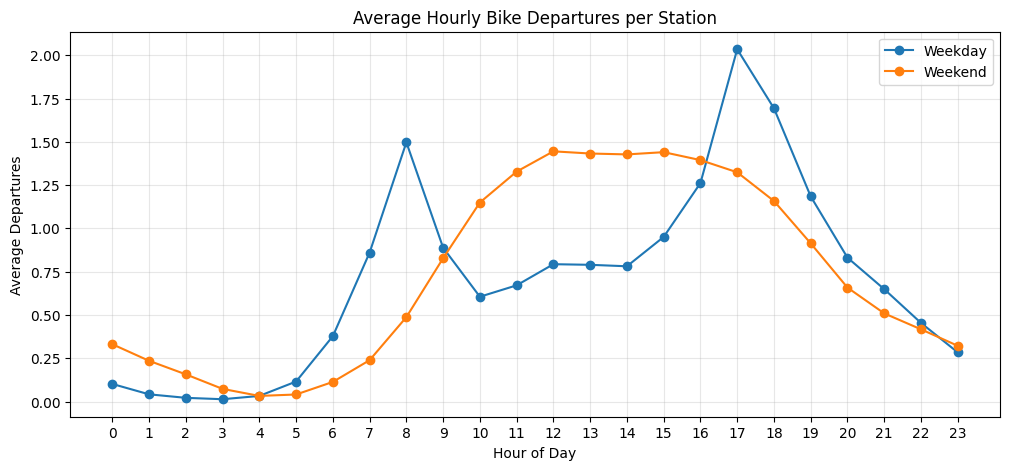

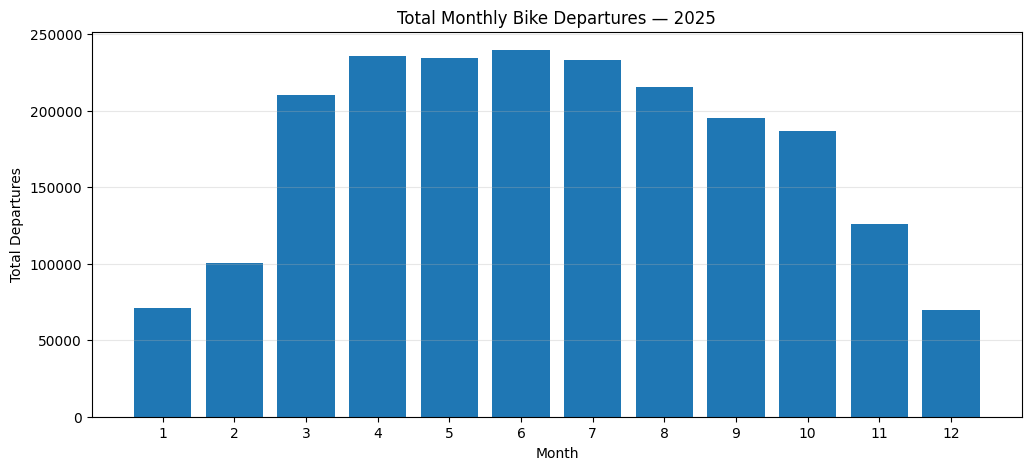


Top 10 stations with largest annual net imbalance:


,departures,arrivals,net_change,absolute_imbalance
station_id,,,,
31225,7567,11507,3940,3940
31102,8537,4842,-3695,3695
31215,6274,9338,3064,3064
31602,7389,4329,-3060,3060
31293,4365,6893,2528,2528
31135,6509,4120,-2389,2389
31131,5972,3639,-2333,2333
30200,6843,8987,2144,2144
31323,7178,5069,-2109,2109


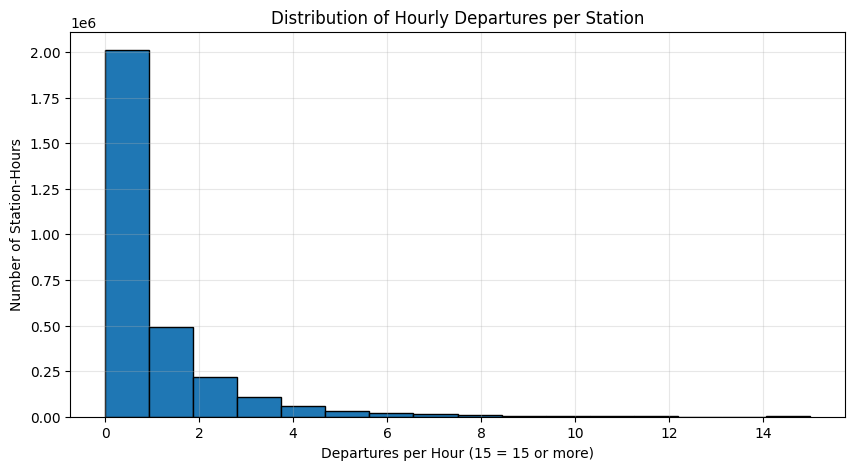

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Load our processed dataset
df = pd.read_parquet(
    "/content/data/hourly_station_demand_2025.parquet"
)

# Add calendar features
df["hour_of_day"] = df["hour"].dt.hour
df["day_of_week"] = df["hour"].dt.dayofweek
df["month"] = df["hour"].dt.month
df["is_weekend"] = df["day_of_week"] >= 5

print(f"Stations: {df['station_id'].nunique()}")
print(f"Observations: {len(df):,}")

# --------------------------------------------------
# 1. WEEKDAY VS WEEKEND DEMAND
# --------------------------------------------------

patterns = (
    df.groupby(["is_weekend", "hour_of_day"])["departures"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

for weekend, label in [(False, "Weekday"), (True, "Weekend")]:
    subset = patterns[patterns["is_weekend"] == weekend]

    plt.plot(
        subset["hour_of_day"],
        subset["departures"],
        marker="o",
        label=label
    )

plt.title("Average Hourly Bike Departures per Station")
plt.xlabel("Hour of Day")
plt.ylabel("Average Departures")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# --------------------------------------------------
# 2. MONTHLY DEMAND
# --------------------------------------------------

monthly = (
    df.groupby("month")["departures"]
    .sum()
)

plt.figure(figsize=(12, 5))
plt.bar(monthly.index, monthly.values)

plt.title("Total Monthly Bike Departures — 2025")
plt.xlabel("Month")
plt.ylabel("Total Departures")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)
plt.show()


# --------------------------------------------------
# 3. STATION IMBALANCE
# --------------------------------------------------

station_imbalance = (
    df.groupby("station_id")
    .agg(
        departures=("departures", "sum"),
        arrivals=("arrivals", "sum")
    )
)

station_imbalance["net_change"] = (
    station_imbalance["arrivals"]
    - station_imbalance["departures"]
)

station_imbalance["absolute_imbalance"] = (
    station_imbalance["net_change"].abs()
)

print("\nTop 10 stations with largest annual net imbalance:")

display(
    station_imbalance.sort_values(
        "absolute_imbalance",
        ascending=False
    ).head(10)
)


# --------------------------------------------------
# 4. HOURLY DEMAND DISTRIBUTION
# --------------------------------------------------

plt.figure(figsize=(10, 5))

df["departures"].clip(upper=15).hist(
    bins=16,
    edgecolor="black"
)

plt.title("Distribution of Hourly Departures per Station")
plt.xlabel("Departures per Hour (15 = 15 or more)")
plt.ylabel("Number of Station-Hours")
plt.grid(alpha=0.3)
plt.show()

In [16]:
import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. LOAD ORIGINAL AGGREGATED DATA
# --------------------------------------------------

df = pd.read_parquet(
    "/content/data/hourly_station_demand.parquet"
)

df["hour"] = pd.to_datetime(df["hour"])
df["station_id"] = df["station_id"].astype(str)

print("Original observations:", f"{len(df):,}")
print("Unique stations:", df["station_id"].nunique())
print("Date range:", df["hour"].min(), "to", df["hour"].max())


# --------------------------------------------------
# 2. SELECT STATIONS USING ONLY 2024 DATA
# --------------------------------------------------

df_2024 = df[
    (df["hour"] >= "2024-01-01") &
    (df["hour"] < "2025-01-01")
].copy()

station_stats = (
    df_2024.groupby("station_id")
    .agg(
        departures=("departures", "sum"),
        arrivals=("arrivals", "sum"),
        first_seen=("hour", "min"),
        last_seen=("hour", "max")
    )
)

station_stats["total_trips"] = (
    station_stats["departures"] +
    station_stats["arrivals"]
)

# Select stations with:
# - At least 3,000 trips in 2024
# - Activity in January 2024
# - Activity in December 2024

selected_stations = station_stats[
    (station_stats["total_trips"] >= 3000) &
    (station_stats["first_seen"] < "2024-02-01") &
    (station_stats["last_seen"] >= "2024-12-01")
].index

print("\nSTATION SELECTION")
print("-----------------------")
print("Selected stations:", len(selected_stations))


# --------------------------------------------------
# 3. FILTER TO SELECTED STATIONS
# --------------------------------------------------

df = df[
    df["station_id"].isin(selected_stations)
].copy()


# --------------------------------------------------
# 4. BUILD COMPLETE HOURLY GRID
# --------------------------------------------------

all_hours = pd.date_range(
    start="2022-01-01 00:00:00",
    end="2025-12-31 23:00:00",
    freq="h"
)

full_index = pd.MultiIndex.from_product(
    [selected_stations, all_hours],
    names=["station_id", "hour"]
)

hourly_complete = (
    df.set_index(["station_id", "hour"])[
        ["departures", "arrivals"]
    ]
    .reindex(full_index, fill_value=0)
    .reset_index()
)

hourly_complete["departures"] = (
    hourly_complete["departures"].astype("int32")
)

hourly_complete["arrivals"] = (
    hourly_complete["arrivals"].astype("int32")
)

hourly_complete["net_change"] = (
    hourly_complete["arrivals"] -
    hourly_complete["departures"]
)

print("\nCOMPLETE DATASET")
print("-----------------------")
print("Total observations:", f"{len(hourly_complete):,}")
print("Stations:", hourly_complete["station_id"].nunique())
print("Hours:", hourly_complete["hour"].nunique())

zero_pct = (
    (hourly_complete["departures"] == 0) &
    (hourly_complete["arrivals"] == 0)
).mean() * 100

print(f"Zero-activity station-hours: {zero_pct:.1f}%")


# --------------------------------------------------
# 5. ADD CALENDAR FEATURES
# --------------------------------------------------

hourly_complete["hour_of_day"] = (
    hourly_complete["hour"].dt.hour
)

hourly_complete["day_of_week"] = (
    hourly_complete["hour"].dt.dayofweek
)

hourly_complete["month"] = (
    hourly_complete["hour"].dt.month
)

hourly_complete["day_of_year"] = (
    hourly_complete["hour"].dt.dayofyear
)

hourly_complete["is_weekend"] = (
    hourly_complete["day_of_week"] >= 5
).astype("int8")


# --------------------------------------------------
# 6. CREATE CHRONOLOGICAL SPLITS
# --------------------------------------------------

train = hourly_complete[
    hourly_complete["hour"] < "2025-01-01"
].copy()

test = hourly_complete[
    hourly_complete["hour"] >= "2025-01-01"
].copy()

print("\nDATASET SPLITS")
print("-----------------------")
print(f"Training: {len(train):,}")
print(f"Testing:  {len(test):,}")

print("\nTRAINING PERIOD")
print(train["hour"].min(), "to", train["hour"].max())

print("\nTESTING PERIOD")
print(test["hour"].min(), "to", test["hour"].max())


# --------------------------------------------------
# 7. SAVE DATASET
# --------------------------------------------------

output_path = "/content/data/hourly_station_demand_4yr.parquet"

hourly_complete.to_parquet(
    output_path,
    index=False
)

print("\nSaved to:", output_path)

Original observations: 7,033,537
Unique stations: 865
Date range: 2022-01-01 00:00:00 to 2025-12-31 23:00:00

STATION SELECTION
-----------------------
Selected stations: 345

COMPLETE DATASET
-----------------------
Total observations: 12,097,080
Stations: 345
Hours: 35064
Zero-activity station-hours: 52.5%

DATASET SPLITS
-----------------------
Training: 9,074,880
Testing:  3,022,200

TRAINING PERIOD
2022-01-01 00:00:00 to 2024-12-31 23:00:00

TESTING PERIOD
2025-01-01 00:00:00 to 2025-12-31 23:00:00

Saved to: /content/data/hourly_station_demand_4yr.parquet


In [17]:
!pip -q install xgboost

import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

df = pd.read_parquet(
    "/content/data/hourly_station_demand_4yr.parquet"
)

# Treat station IDs as categorical
df["station_id"] = df["station_id"].astype("category")

features = [
    "station_id",
    "hour_of_day",
    "day_of_week",
    "month",
    "day_of_year",
    "is_weekend"
]

# --------------------------------------------------
# 2. SPLIT DATA
# --------------------------------------------------

train = df[df["hour"] < "2025-01-01"]
test = df[df["hour"] >= "2025-01-01"]

print(f"Training observations: {len(train):,}")
print(f"Testing observations:  {len(test):,}")

# --------------------------------------------------
# 3. TRAIN XGBOOST
# --------------------------------------------------

model = XGBRegressor(
    objective="count:poisson",
    n_estimators=300,
    max_depth=7,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    enable_categorical=True,
    n_jobs=-1,
    random_state=42
)

print("\nTraining XGBoost...")

model.fit(
    train[features],
    train["departures"],
    verbose=False
)

# --------------------------------------------------
# 4. PREDICT
# --------------------------------------------------

predictions = model.predict(test[features])
y_true = test["departures"].to_numpy()

# --------------------------------------------------
# 5. EVALUATE
# --------------------------------------------------

mae = mean_absolute_error(y_true, predictions)
rmse = np.sqrt(mean_squared_error(y_true, predictions))

wape = (
    np.abs(y_true - predictions).sum()
    / y_true.sum()
    * 100
)

busy = y_true >= 3
busy_mae = mean_absolute_error(
    y_true[busy],
    predictions[busy]
) if busy.any() else np.nan

bias = np.mean(predictions - y_true)

# Zero baseline
zero_mae = mean_absolute_error(
    y_true,
    np.zeros_like(y_true)
)

# Historical average baseline
group_cols = ["station_id", "day_of_week", "hour_of_day"]

historical_avg = (
    train.groupby(group_cols, observed=True)["departures"]
    .mean()
    .rename("baseline_prediction")
    .reset_index()
)

test_baseline = test.merge(
    historical_avg,
    on=group_cols,
    how="left"
)

baseline_predictions = (
    test_baseline["baseline_prediction"]
    .fillna(train["departures"].mean())
    .to_numpy()
)

historical_mae = mean_absolute_error(
    y_true,
    baseline_predictions
)

# --------------------------------------------------
# 6. RESULTS
# --------------------------------------------------

print("\nXGBOOST RESULTS")
print("-----------------------")
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"WAPE: {wape:.1f}%")
print(f"Busy-Hour MAE: {busy_mae:.3f}")
print(f"Prediction Bias: {bias:+.3f}")

print("\nBASELINE COMPARISON")
print("-----------------------")
print(f"Zero baseline MAE:       {zero_mae:.3f}")
print(f"Historical average MAE:  {historical_mae:.3f}")
print(f"XGBoost MAE:             {mae:.3f}")

print("\nACTUAL VS PREDICTED")
print("-----------------------")
print(f"Actual mean departures:    {y_true.mean():.3f}")
print(f"Predicted mean departures: {predictions.mean():.3f}")

Training observations: 9,074,880
Testing observations:  3,022,200

Training XGBoost...


KeyboardInterrupt: 

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_parquet(
    "/content/data/hourly_station_demand_4yr.parquet"
)

# Sort chronologically within each station
df = df.sort_values(
    ["station_id", "hour"]
).reset_index(drop=True)

# Group by station
grouped = df.groupby("station_id")["departures"]

# Lag features
for lag in [1, 3, 24, 168]:
    df[f"departures_lag_{lag}"] = grouped.shift(lag)

# Rolling averages based strictly on previous observations
for window in [6, 24]:
    df[f"departures_rolling_{window}h"] = (
        df.groupby("station_id")["departures"]
        .transform(
            lambda x: x.shift(1).rolling(window).mean()
        )
    )

# Drop rows without sufficient history
df = df.dropna().copy()

# Save feature-enriched dataset
output_path = "/content/data/hourly_station_demand_features.parquet"

df.to_parquet(output_path, index=False)

print("Feature engineering complete.")
print(f"Observations: {len(df):,}")
print(f"Features: {len(df.columns)}")

print("\nNew features:")
print([
    col for col in df.columns
    if "lag" in col or "rolling" in col
])


In [ ]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# --------------------------------------------------
# 1. LOAD FEATURE-ENRICHED DATASET
# --------------------------------------------------

df = pd.read_parquet(
    "/content/data/hourly_station_demand_features.parquet"
)

df["station_id"] = df["station_id"].astype("category")

# --------------------------------------------------
# 2. DEFINE FEATURES
# --------------------------------------------------

features = [
    # Station
    "station_id",

    # Calendar
    "hour_of_day",
    "day_of_week",
    "month",
    "day_of_year",
    "is_weekend",

    # Historical demand
    "departures_lag_1",
    "departures_lag_3",
    "departures_lag_24",
    "departures_lag_168",
    "departures_rolling_6h",
    "departures_rolling_24h"
]

# --------------------------------------------------
# 3. TRAIN / TEST SPLIT
# --------------------------------------------------

train = df[df["hour"] < "2025-01-01"]
test = df[df["hour"] >= "2025-01-01"]

print(f"Training observations: {len(train):,}")
print(f"Testing observations:  {len(test):,}")

# --------------------------------------------------
# 4. TRAIN XGBOOST
# --------------------------------------------------

model_lags = XGBRegressor(
    objective="count:poisson",
    n_estimators=300,
    max_depth=7,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    enable_categorical=True,
    n_jobs=-1,
    random_state=42
)

print("\nTraining XGBoost with lag features...")

model_lags.fit(
    train[features],
    train["departures"],
    verbose=False
)

# --------------------------------------------------
# 5. PREDICT
# --------------------------------------------------

predictions_lags = model_lags.predict(test[features])
y_true = test["departures"].to_numpy()

# --------------------------------------------------
# 6. EVALUATE
# --------------------------------------------------

mae = mean_absolute_error(y_true, predictions_lags)

rmse = np.sqrt(
    mean_squared_error(y_true, predictions_lags)
)

wape = (
    np.abs(y_true - predictions_lags).sum()
    / y_true.sum()
    * 100
)

busy = y_true >= 3

busy_mae = mean_absolute_error(
    y_true[busy],
    predictions_lags[busy]
) if busy.any() else np.nan

bias = np.mean(predictions_lags - y_true)

# Zero baseline
zero_mae = mean_absolute_error(
    y_true,
    np.zeros_like(y_true)
)

# --------------------------------------------------
# 7. RESULTS
# --------------------------------------------------

print("\nXGBOOST WITH LAG FEATURES")
print("-----------------------------")
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"WAPE: {wape:.1f}%")
print(f"Busy-Hour MAE: {busy_mae:.3f}")
print(f"Prediction Bias: {bias:+.3f}")

print("\nMODEL COMPARISON")
print("-----------------------------")
print(f"Zero baseline MAE:       {zero_mae:.3f}")
print("Previous XGBoost MAE:    0.717")
print(f"XGBoost with lags MAE:   {mae:.3f}")

print("\nACTUAL VS PREDICTED")
print("-----------------------------")
print(f"Actual mean departures:    {y_true.mean():.3f}")
print(f"Predicted mean departures: {predictions_lags.mean():.3f}")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

df = pd.read_parquet(
    "/content/data/hourly_station_demand.parquet"
)

# Only use training years
df = df[df["hour"] < "2025-01-01"].copy()

# --------------------------------------------------
# 2. CALCULATE ACTIVITY PER STATION
# --------------------------------------------------

station_activity = (
    df.groupby("station_id")
    .agg(
        departures=("departures", "sum"),
        arrivals=("arrivals", "sum")
    )
)

station_activity["total_activity"] = (
    station_activity["departures"] +
    station_activity["arrivals"]
)

# Rank stations by activity
station_activity = station_activity.sort_values(
    "total_activity",
    ascending=False
)

# Calculate cumulative percentage
station_activity["cumulative_share"] = (
    station_activity["total_activity"].cumsum()
    / station_activity["total_activity"].sum()
)

# --------------------------------------------------
# 3. ACTIVITY CONCENTRATION
# --------------------------------------------------

print("STATION ACTIVITY CONCENTRATION (2022–2024)")
print("------------------------------------------")
print(f"Total stations: {len(station_activity)}")

for threshold in [0.50, 0.60, 0.70, 0.80, 0.90]:
    n = np.searchsorted(
        station_activity["cumulative_share"].values,
        threshold
    ) + 1

    print(
        f"{threshold:.0%} of activity: "
        f"{n} stations "
        f"({n / len(station_activity):.1%} of stations)"
    )

print("\nACTIVITY COVERAGE BY STATION COUNT")
print("------------------------------------------")

for n in [25, 50, 75, 100, 125, 150, 200, 250, 300]:
    if n <= len(station_activity):
        share = station_activity["cumulative_share"].iloc[n - 1]

        print(f"Top {n:3d} stations: {share:.1%} of activity")

# --------------------------------------------------
# 4. VISUALIZE
# --------------------------------------------------

plt.figure(figsize=(11, 6))

plt.plot(
    np.arange(1, len(station_activity) + 1),
    station_activity["cumulative_share"] * 100,
    linewidth=2
)

plt.axhline(
    80,
    linestyle="--",
    color="red",
    label="80% activity threshold"
)

n_80 = np.searchsorted(
    station_activity["cumulative_share"].values,
    0.80
) + 1

plt.axvline(
    n_80,
    linestyle="--",
    color="green",
    label=f"{n_80} stations"
)

plt.xlabel("Number of stations")
plt.ylabel("Cumulative share of activity (%)")
plt.title("Capital Bikeshare Station Activity Concentration (2022–2024)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error

# station_activity was created in our previous analysis.
# It is already ranked by 2022–2024 activity.

# Our existing test dataset and predictions
evaluation = test[["station_id", "hour", "departures"]].copy()

evaluation["prediction"] = predictions_lags

# Normalize station IDs for matching
evaluation["station_id"] = evaluation["station_id"].astype(str)

ranked_stations = station_activity.index.astype(str).tolist()

print("FORECAST PERFORMANCE BY STATION COUNT")
print("------------------------------------------------------------")
print(f"{'Stations':<12}{'2025 Activity Share':<22}{'MAE':<12}{'Zero MAE':<12}")
print("------------------------------------------------------------")

for n in [50, 75, 100, 125, 150, 200, 213]:

    selected = set(ranked_stations[:n])

    subset = evaluation[
        evaluation["station_id"].isin(selected)
    ]

    if len(subset) == 0:
        continue

    mae = mean_absolute_error(
        subset["departures"],
        subset["prediction"]
    )

    zero_mae = subset["departures"].mean()

    print(
        f"{n:<12}"
        f"{'—':<22}"
        f"{mae:<12.3f}"
        f"{zero_mae:<12.3f}"
    )

In [ ]:
import pandas as pd
import numpy as np

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

df = pd.read_parquet(
    "/content/data/hourly_station_demand_features.parquet"
)

df["station_id"] = df["station_id"].astype(str)

# --------------------------------------------------
# 2. RANK STATIONS BY 2024 ACTIVITY
# --------------------------------------------------

df_2024 = df[
    (df["hour"] >= "2024-01-01") &
    (df["hour"] < "2025-01-01")
]

station_activity = (
    df_2024.groupby("station_id")
    .agg(
        departures=("departures", "sum"),
        arrivals=("arrivals", "sum")
    )
)

station_activity["total_activity"] = (
    station_activity["departures"] +
    station_activity["arrivals"]
)

station_activity = station_activity.sort_values(
    "total_activity",
    ascending=False
)

# Select top 100
top_100_stations = station_activity.head(100).index.tolist()

print("Selected stations:", len(top_100_stations))

# --------------------------------------------------
# 3. FILTER DATASET
# --------------------------------------------------

df_100 = df[
    df["station_id"].isin(top_100_stations)
].copy()

# --------------------------------------------------
# 4. TRAIN / TEST SPLIT
# --------------------------------------------------

train_100 = df_100[
    df_100["hour"] < "2025-01-01"
].copy()

test_100 = df_100[
    df_100["hour"] >= "2025-01-01"
].copy()

# --------------------------------------------------
# 5. SAVE DATASET
# --------------------------------------------------

output_path = "/content/data/hourly_station_demand_top100.parquet"

df_100.to_parquet(output_path, index=False)

print("\nTOP 100 DATASET")
print("-------------------------------")
print(f"Total observations: {len(df_100):,}")
print(f"Training observations: {len(train_100):,}")
print(f"Testing observations: {len(test_100):,}")

print("\n2024 ACTIVITY COVERAGE")

coverage = (
    station_activity.head(100)["total_activity"].sum()
    / station_activity["total_activity"].sum()
)

print(f"Top 100 share of activity: {coverage:.1%}")

print("\nSaved to:", output_path)

In [ ]:
import pandas as pd
import numpy as np

# Load 100-station dataset
df = pd.read_parquet(
    "/content/data/hourly_station_demand_top100.parquet"
)

# Sort chronologically
df = df.sort_values(
    ["station_id", "hour"]
).reset_index(drop=True)

# --------------------------------------------------
# CREATE 3-HOUR FORECAST TARGETS
# --------------------------------------------------

grouped = df.groupby("station_id", sort=False)

# Current hour + next two hours
df["departures_next_3h"] = (
    df["departures"]
    + grouped["departures"].shift(-1)
    + grouped["departures"].shift(-2)
)

df["arrivals_next_3h"] = (
    df["arrivals"]
    + grouped["arrivals"].shift(-1)
    + grouped["arrivals"].shift(-2)
)

df["net_change_next_3h"] = (
    df["arrivals_next_3h"]
    - df["departures_next_3h"]
)

# Remove final two hours per station
df = df.dropna(
    subset=["departures_next_3h", "arrivals_next_3h"]
).copy()

# --------------------------------------------------
# SAVE
# --------------------------------------------------

output_path = "/content/data/hourly_station_demand_top100_3h.parquet"

df.to_parquet(output_path, index=False)

print("THREE-HOUR FORECASTING DATASET")
print("--------------------------------")
print(f"Stations: {df['station_id'].nunique()}")
print(f"Observations: {len(df):,}")

print("\nAverage 3-hour demand:")
print(f"Departures: {df['departures_next_3h'].mean():.2f}")
print(f"Arrivals:   {df['arrivals_next_3h'].mean():.2f}")

print("\nSaved to:", output_path)

In [ ]:
import pandas as pd
import numpy as np
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------

df = pd.read_parquet(
    "/content/data/hourly_station_demand_top100_3h.parquet"
)

df = df.sort_values(
    ["station_id", "hour"]
).reset_index(drop=True)

# --------------------------------------------------
# 2. ADD ARRIVAL LAG FEATURES
# --------------------------------------------------

grouped = df.groupby("station_id")["arrivals"]

for lag in [1, 3, 24, 168]:
    df[f"arrivals_lag_{lag}"] = grouped.shift(lag)

for window in [6, 24]:
    df[f"arrivals_rolling_{window}h"] = (
        df.groupby("station_id")["arrivals"]
        .transform(
            lambda x: x.shift(1).rolling(window).mean()
        )
    )

df = df.dropna().copy()

# Station IDs as categorical variables
df["station_id"] = df["station_id"].astype("category")

# --------------------------------------------------
# 3. DEFINE FEATURES
# --------------------------------------------------

features = [
    "station_id",
    "hour_of_day",
    "day_of_week",
    "month",
    "day_of_year",
    "is_weekend",

    "departures_lag_1",
    "departures_lag_3",
    "departures_lag_24",
    "departures_lag_168",
    "departures_rolling_6h",
    "departures_rolling_24h",

    "arrivals_lag_1",
    "arrivals_lag_3",
    "arrivals_lag_24",
    "arrivals_lag_168",
    "arrivals_rolling_6h",
    "arrivals_rolling_24h"
]

# --------------------------------------------------
# 4. TRAIN / TEST SPLIT
# --------------------------------------------------

# Exclude training rows whose 3-hour target
# extends into 2025.
train = df[
    df["hour"] < "2024-12-31 22:00:00"
].copy()

# Test on all available 2025 forecast windows.
test = df[
    df["hour"] >= "2025-01-01"
].copy()

print(f"Training observations: {len(train):,}")
print(f"Testing observations:  {len(test):,}")

# --------------------------------------------------
# 5. TRAIN MODELS
# --------------------------------------------------

models = {}
predictions = {}

targets = {
    "departures": "departures_next_3h",
    "arrivals": "arrivals_next_3h"
}

for name, target in targets.items():

    print(f"\nTraining {name} model...")

    model = XGBRegressor(
        objective="count:poisson",
        n_estimators=300,
        max_depth=7,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        enable_categorical=True,
        n_jobs=-1,
        random_state=42
    )

    model.fit(
        train[features],
        train[target],
        verbose=False
    )

    predictions[name] = model.predict(test[features])
    models[name] = model

# --------------------------------------------------
# 6. EVALUATE
# --------------------------------------------------

print("\nTHREE-HOUR FORECASTING RESULTS")
print("--------------------------------------------------")

for name, target in targets.items():

    actual = test[target].to_numpy()
    predicted = predictions[name]

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    zero_mae = mean_absolute_error(
        actual,
        np.zeros_like(actual)
    )

    bias = np.mean(predicted - actual)

    print(f"\n{name.upper()}")
    print(f"MAE:             {mae:.3f}")
    print(f"RMSE:            {rmse:.3f}")
    print(f"Zero MAE:        {zero_mae:.3f}")
    print(f"Prediction bias: {bias:+.3f}")

# --------------------------------------------------
# 7. SAVE FORECASTS
# --------------------------------------------------

forecast_results = test[
    ["station_id", "hour",
     "departures_next_3h",
     "arrivals_next_3h"]
].copy()

forecast_results["predicted_departures"] = (
    predictions["departures"]
)

forecast_results["predicted_arrivals"] = (
    predictions["arrivals"]
)

forecast_results["predicted_net_change"] = (
    forecast_results["predicted_arrivals"]
    - forecast_results["predicted_departures"]
)

forecast_results.to_parquet(
    "/content/data/three_hour_forecasts_2025.parquet",
    index=False
)

print("\nForecasts saved successfully.")

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ==================================================
# PHASE 1: MODEL EVALUATION
# ==================================================

targets = {
    "departures": "departures_next_3h",
    "arrivals": "arrivals_next_3h"
}

# --------------------------------------------------
# 1. BASELINE COMPARISON
# --------------------------------------------------

print("=" * 60)
print("1. BASELINE COMPARISON")
print("=" * 60)

for name, target in targets.items():

    actual = test[target].to_numpy()
    xgb_pred = predictions[name]

    # Baseline 1: Always predict zero
    zero_pred = np.zeros_like(actual)

    # Baseline 2: Historical station/hour/weekday average
    historical = (
        train.groupby(
            ["station_id", "hour_of_day", "day_of_week"],
            observed=True
        )[target]
        .mean()
        .rename("historical_prediction")
        .reset_index()
    )

    baseline_df = test[
        ["station_id", "hour_of_day", "day_of_week"]
    ].merge(
        historical,
        on=["station_id", "hour_of_day", "day_of_week"],
        how="left",
        sort=False
    )

    # Fallback for unseen combinations
    station_means = train.groupby(
        "station_id",
        observed=True
    )[target].mean()

    historical_pred = (
        baseline_df["historical_prediction"]
        .fillna(
            test["station_id"].map(station_means)
            .astype(float)
            .reset_index(drop=True)
        )
        .to_numpy()
    )

    # Baseline 3: Previous week's demand
    # Uses the same 3-hour target from 168 hours earlier.
    # This is a valid baseline if historical demand
    # is available at forecast time.
    weekly_lookup = df[
        ["station_id", "hour", target]
    ].copy()

    weekly_lookup["hour"] = (
        weekly_lookup["hour"] + pd.Timedelta(hours=168)
    )

    weekly_lookup = weekly_lookup.rename(
        columns={target: "weekly_prediction"}
    )

    weekly_df = test[
        ["station_id", "hour"]
    ].merge(
        weekly_lookup,
        on=["station_id", "hour"],
        how="left",
        sort=False
    )

    weekly_pred = weekly_df[
        "weekly_prediction"
    ].to_numpy()

    valid_weekly = ~np.isnan(weekly_pred)

    results = {
        "Zero baseline": mean_absolute_error(
            actual, zero_pred
        ),
        "Historical average": mean_absolute_error(
            actual, historical_pred
        ),
        "Seasonal naive (7d)": mean_absolute_error(
            actual[valid_weekly],
            weekly_pred[valid_weekly]
        ),
        "XGBoost": mean_absolute_error(
            actual, xgb_pred
        )
    }

    print(f"\n{name.upper()}")

    for model_name, mae in results.items():
        print(f"{model_name:<25} MAE: {mae:.3f}")

    improvement = (
        1 - results["XGBoost"] /
        results["Historical average"]
    ) * 100

    print(
        f"\nXGBoost improvement over historical: "
        f"{improvement:.1f}%"
    )


# --------------------------------------------------
# 2. PERFORMANCE BY DEMAND LEVEL
# --------------------------------------------------

print("\n" + "=" * 60)
print("2. PERFORMANCE BY DEMAND LEVEL")
print("=" * 60)

bins = [-0.1, 2, 5, 10, 20, np.inf]

labels = [
    "Very low (0-2)",
    "Low (3-5)",
    "Medium (6-10)",
    "High (11-20)",
    "Very high (21+)"
]

for name, target in targets.items():

    evaluation = pd.DataFrame({
        "actual": test[target].to_numpy(),
        "predicted": predictions[name]
    })

    evaluation["absolute_error"] = abs(
        evaluation["actual"] -
        evaluation["predicted"]
    )

    evaluation["error"] = (
        evaluation["predicted"] -
        evaluation["actual"]
    )

    evaluation["demand_category"] = pd.cut(
        evaluation["actual"],
        bins=bins,
        labels=labels
    )

    summary = (
        evaluation.groupby(
            "demand_category",
            observed=True
        )
        .agg(
            observations=("actual", "count"),
            average_demand=("actual", "mean"),
            MAE=("absolute_error", "mean"),
            bias=("error", "mean")
        )
    )

    print(f"\n{name.upper()}")
    print(summary.round(3).to_string())


# --------------------------------------------------
# 3. NET-FLOW PREDICTION ACCURACY
# --------------------------------------------------

print("\n" + "=" * 60)
print("3. NET-FLOW PREDICTION ACCURACY")
print("=" * 60)

actual_net = (
    test["arrivals_next_3h"].to_numpy()
    - test["departures_next_3h"].to_numpy()
)

predicted_net = (
    predictions["arrivals"]
    - predictions["departures"]
)

net_mae = mean_absolute_error(
    actual_net,
    predicted_net
)

net_rmse = np.sqrt(
    mean_squared_error(
        actual_net,
        predicted_net
    )
)

net_bias = np.mean(
    predicted_net - actual_net
)

print(f"\nNet-flow MAE:  {net_mae:.3f}")
print(f"Net-flow RMSE: {net_rmse:.3f}")
print(f"Net-flow bias: {net_bias:+.3f}")

print("\nPHASE 1 EVALUATION COMPLETE")

In [ ]:
import pandas as pd
import numpy as np

print("=" * 65)
print("PREDICTION CALIBRATION ANALYSIS")
print("=" * 65)

bins = [0, 2, 5, 10, 20, np.inf]

labels = [
    "Very low (0-2)",
    "Low (2-5)",
    "Medium (5-10)",
    "High (10-20)",
    "Very high (20+)"
]

for name, target in targets.items():

    evaluation = pd.DataFrame({
        "actual": test[target].to_numpy(),
        "predicted": predictions[name]
    })

    evaluation["error"] = (
        evaluation["predicted"] -
        evaluation["actual"]
    )

    evaluation["absolute_error"] = abs(
        evaluation["error"]
    )

    # Group by PREDICTED demand, not actual demand
    evaluation["prediction_category"] = pd.cut(
        evaluation["predicted"],
        bins=bins,
        labels=labels,
        include_lowest=True
    )

    summary = (
        evaluation.groupby(
            "prediction_category",
            observed=True
        )
        .agg(
            observations=("actual", "count"),
            avg_prediction=("predicted", "mean"),
            avg_actual=("actual", "mean"),
            MAE=("absolute_error", "mean"),
            bias=("error", "mean")
        )
    )

    print(f"\n{name.upper()}")
    print(summary.round(3).to_string())

    print(
        f"\nOverall bias: "
        f"{evaluation['error'].mean():+.3f}"
    )

In [ ]:
import pandas as pd

df = pd.read_parquet(
    "/content/data/hourly_station_demand_top100.parquet"
)

df["hour"] = pd.to_datetime(df["hour"])

df = df.sort_values(
    ["station_id", "hour"]
).reset_index(drop=True)

# Difference between consecutive timestamps
df["hour_gap"] = (
    df.groupby("station_id")["hour"]
    .diff()
)

# Identify gaps larger than one hour
gaps = df[
    df["hour_gap"] > pd.Timedelta(hours=1)
]

# Identify duplicate station-hour observations
duplicates = df.duplicated(
    subset=["station_id", "hour"]
).sum()

print("DATA CONTINUITY CHECK")
print("-" * 40)

print(f"Stations: {df['station_id'].nunique()}")
print(f"Total observations: {len(df):,}")
print(f"Missing hourly gaps: {len(gaps):,}")
print(f"Duplicate station-hours: {duplicates:,}")

if len(gaps) > 0:
    print("\nLargest gaps:")
    print(
        gaps[
            ["station_id", "hour", "hour_gap"]
        ]
        .sort_values("hour_gap", ascending=False)
        .head(10)
        .to_string(index=False)
    )

print("\nDate range:")
print("Start:", df["hour"].min())
print("End:  ", df["hour"].max())

In [ ]:
import pandas as pd
import numpy as np

# Load original dataset and model dataset
raw = pd.read_parquet(
    "/content/data/hourly_station_demand_top100.parquet"
)

model_df = pd.read_parquet(
    "/content/data/hourly_station_demand_top100_3h.parquet"
)

raw = raw.sort_values(
    ["station_id", "hour"]
).reset_index(drop=True)

model_df = model_df.sort_values(
    ["station_id", "hour"]
).reset_index(drop=True)

print("=" * 55)
print("FEATURE LEAKAGE CHECK")
print("=" * 55)

# Recalculate departure features independently
grouped = raw.groupby("station_id")["departures"]

for lag in [1, 3, 24, 168]:

    expected = grouped.shift(lag)

    comparison = raw[
        ["station_id", "hour"]
    ].copy()

    comparison["expected"] = expected

    comparison = model_df[
        ["station_id", "hour", f"departures_lag_{lag}"]
    ].merge(
        comparison,
        on=["station_id", "hour"],
        how="left",
        validate="one_to_one"
    )

    actual = comparison[f"departures_lag_{lag}"]

    matches = np.isclose(
        actual.to_numpy(dtype=float),
        comparison["expected"].to_numpy(dtype=float),
        equal_nan=True
    )

    print(
        f"departures_lag_{lag}: "
        f"{matches.mean() * 100:.2f}% match"
    )

# Recalculate rolling features independently
for window in [6, 24]:

    expected = (
        raw.groupby("station_id")["departures"]
        .transform(
            lambda x: x.shift(1).rolling(window).mean()
        )
    )

    comparison = raw[
        ["station_id", "hour"]
    ].copy()

    comparison["expected"] = expected

    comparison = model_df[
        ["station_id", "hour",
         f"departures_rolling_{window}h"]
    ].merge(
        comparison,
        on=["station_id", "hour"],
        how="left",
        validate="one_to_one"
    )

    actual = comparison[
        f"departures_rolling_{window}h"
    ]

    matches = np.isclose(
        actual.to_numpy(dtype=float),
        comparison["expected"].to_numpy(dtype=float),
        equal_nan=True
    )

    print(
        f"departures_rolling_{window}h: "
        f"{matches.mean() * 100:.2f}% match"
    )

print("\nCHECK COMPLETE")

In [ ]:
import pandas as pd
import numpy as np

raw = pd.read_parquet(
    "/content/data/hourly_station_demand_top100.parquet"
)

raw = raw.sort_values(
    ["station_id", "hour"]
).reset_index(drop=True)

grouped = raw.groupby("station_id")["departures"]

print("VALID FEATURE COMPARISON")
print("-" * 45)

for lag in [1, 3, 24, 168]:

    feature = f"departures_lag_{lag}"

    expected = grouped.shift(lag)

    valid = raw[feature].notna() & expected.notna()

    matches = np.isclose(
        raw.loc[valid, feature],
        expected.loc[valid]
    )

    print(
        f"{feature}: "
        f"{matches.mean() * 100:.4f}% match "
        f"({valid.sum():,} valid rows)"
    )

for window in [6, 24]:

    feature = f"departures_rolling_{window}h"

    expected = (
        grouped.transform(
            lambda x: x.shift(1).rolling(window).mean()
        )
    )

    valid = raw[feature].notna() & expected.notna()

    matches = np.isclose(
        raw.loc[valid, feature],
        expected.loc[valid]
    )

    print(
        f"{feature}: "
        f"{matches.mean() * 100:.4f}% match "
        f"({valid.sum():,} valid rows)"
    )

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# ================================================
# PHASE 3: FEATURE IMPORTANCE
# ================================================

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, name in zip(axes, ["departures", "arrivals"]):

    model = models[name]

    # XGBoost feature importance (total gain)
    importance = model.get_booster().get_score(
        importance_type="total_gain"
    )

    importance_df = pd.DataFrame({
        "feature": list(importance.keys()),
        "importance": list(importance.values())
    })

    # Normalize to percentages
    importance_df["importance_pct"] = (
        importance_df["importance"]
        / importance_df["importance"].sum()
        * 100
    )

    importance_df = importance_df.sort_values(
        "importance_pct",
        ascending=True
    )

    ax.barh(
        importance_df["feature"],
        importance_df["importance_pct"]
    )

    ax.set_title(
        f"{name.capitalize()} Model — Feature Importance"
    )

    ax.set_xlabel("Share of Total Gain (%)")

plt.tight_layout()
plt.show()

# Print numerical rankings
for name in ["departures", "arrivals"]:

    importance = models[name].get_booster().get_score(
        importance_type="total_gain"
    )

    importance_df = (
        pd.DataFrame(
            importance.items(),
            columns=["feature", "total_gain"]
        )
        .sort_values("total_gain", ascending=False)
    )

    importance_df["share_pct"] = (
        importance_df["total_gain"]
        / importance_df["total_gain"].sum()
        * 100
    )

    print(f"\n{name.upper()} FEATURE IMPORTANCE")
    print("-" * 50)

    print(
        importance_df[
            ["feature", "share_pct"]
        ]
        .round(2)
        .to_string(index=False)
    )

In [ ]:
import numpy as np
import pandas as pd
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error

print("=" * 65)
print("CROSS-FLOW FEATURE ABLATION")
print("=" * 65)

results = []

base_features = [
    "station_id",
    "hour_of_day",
    "day_of_week",
    "month",
    "day_of_year",
    "is_weekend"
]

for name, target in targets.items():

    print(f"\nEvaluating {name.upper()} model...")

    # Only use historical features from the
    # flow being predicted.
    same_flow_features = base_features + [
        f"{name}_lag_1",
        f"{name}_lag_3",
        f"{name}_lag_24",
        f"{name}_lag_168",
        f"{name}_rolling_6h",
        f"{name}_rolling_24h"
    ]

    # Train reduced model
    reduced_model = XGBRegressor(
        objective="count:poisson",
        n_estimators=300,
        max_depth=7,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        tree_method="hist",
        enable_categorical=True,
        n_jobs=-1,
        random_state=42
    )

    reduced_model.fit(
        train[same_flow_features],
        train[target],
        verbose=False
    )

    reduced_predictions = reduced_model.predict(
        test[same_flow_features]
    )

    actual = test[target].to_numpy()

    reduced_mae = mean_absolute_error(
        actual,
        reduced_predictions
    )

    full_mae = mean_absolute_error(
        actual,
        predictions[name]
    )

    improvement = (
        (reduced_mae - full_mae)
        / reduced_mae
        * 100
    )

    results.append({
        "Model": name,
        "Same-flow MAE": reduced_mae,
        "Full-model MAE": full_mae,
        "Cross-flow improvement (%)": improvement
    })

results_df = pd.DataFrame(results)

print("\n" + "=" * 65)
print("ABLATION RESULTS")
print("=" * 65)

print(
    results_df.round(3).to_string(index=False)
)